<a href="https://colab.research.google.com/github/Pratyaydevil/Box-Office/blob/main/EDA_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Welcome to Colab!

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

sns.set_theme(style="whitegrid")


#1Loading the dataset

url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/mroz.csv"

df = pd.read_csv(url)

print("\nFIRST FIVE RECORDS")
print(df.head())

print("\nLAST FIVE RECORDS")
print(df.tail())

print("\nDATASET DIMENSIONS")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nDATASET INFORMATION")
df.info()



FIRST FIVE RECORDS
   rownames  inlf  hours  kidslt6  kidsge6  age  educ    wage  repwage  hushrs  husage  huseduc  huswage  faminc     mtr  motheduc  fatheduc  unem  \
0         1     1   1610        1        0   32    12  3.3540     2.65    2708      34       12   4.0288   16310  0.7215        12         7   5.0   
1         2     1   1656        0        2   30    12  1.3889     2.65    2310      30        9   8.4416   21800  0.6615         7         7  11.0   
2         3     1   1980        1        3   35    12  4.5455     4.04    3072      40       12   3.5807   21040  0.6915        12         7   5.0   
3         4     1    456        0        3   34    12  1.0965     3.25    1920      53       10   3.5417    7300  0.7815         7         7   5.0   
4         5     1   1568        1        2   31    14  4.5918     3.60    2000      32       12  10.0000   27300  0.6215        12        14   9.5   

   city  exper   nwifeinc     lwage  expersq  
0     0     14  10.910060  1.210

In [ ]:
# 2. BASIC STATISTICAL ANALYSIS


print("\nSUMMARY STATISTICS")
print(df.describe().T)

print("\nMEAN OF NUMERICAL COLUMNS")
print(df.mean(numeric_only=True))

print("\nMEDIAN OF NUMERICAL COLUMNS")
print(df.median(numeric_only=True))

print("\nSTANDARD DEVIATION")
print(df.std(numeric_only=True))

print("\nMINIMUM VALUES")
print(df.min(numeric_only=True))

print("\nMAXIMUM VALUES")
print(df.max(numeric_only=True))

print("\nVARIANCE")
print(df.var(numeric_only=True))

print("\nSKEWNESS")
print(df.skew(numeric_only=True))

print("\nNUMBER OF UNIQUE VALUES")
print(df.nunique())

numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

print("\nNUMERICAL COLUMNS")
print(numerical_columns)

print("\nCATEGORICAL COLUMNS")
print(categorical_columns)



SUMMARY STATISTICS
          count          mean           std          min           25%           50%           75%           max
rownames  753.0    377.000000    217.516666     1.000000    189.000000    377.000000    565.000000    753.000000
inlf      753.0      0.568393      0.495630     0.000000      0.000000      1.000000      1.000000      1.000000
hours     753.0    740.576361    871.314216     0.000000      0.000000    288.000000   1516.000000   4950.000000
kidslt6   753.0      0.237716      0.523959     0.000000      0.000000      0.000000      0.000000      3.000000
kidsge6   753.0      1.353254      1.319874     0.000000      0.000000      1.000000      2.000000      8.000000
age       753.0     42.537849      8.072574    30.000000     36.000000     43.000000     49.000000     60.000000
educ      753.0     12.286853      2.280246     5.000000     12.000000     12.000000     13.000000     17.000000
wage      428.0      4.177682      3.310282     0.128200      2.262600      

In [ ]:
# 3. HANDLING MISSING DATA

print("\nMISSING VALUES IN EACH COLUMN")
missing_values = df.isnull().sum()
print(missing_values)

print("\nMISSING VALUE PERCENTAGE")
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage.round(2))

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage.round(2)
})

print("\nMISSING DATA SUMMARY")
print(missing_summary)

print("\nTOTAL MISSING VALUES")
print(df.isnull().sum().sum())

print("\nROWS CONTAINING MISSING VALUES")
print(df[df.isnull().any(axis=1)].head(20))



df_clean = df.copy()

# Replace missing numerical values with median
numeric_columns_with_missing = df_clean.select_dtypes(
    include=np.number
).columns[df_clean.select_dtypes(include=np.number).isnull().any()]

for column in numeric_columns_with_missing:
    median_value = df_clean[column].median()
    df_clean[column] = df_clean[column].fillna(median_value)

# Replace missing categorical values with mode
categorical_columns_with_missing = df_clean.select_dtypes(
    exclude=np.number
).columns[df_clean.select_dtypes(exclude=np.number).isnull().any()]

for column in categorical_columns_with_missing:
    mode_value = df_clean[column].mode()[0]
    df_clean[column] = df_clean[column].fillna(mode_value)

print("\nMISSING VALUES AFTER IMPUTATION")
print(df_clean.isnull().sum())

print("\nTOTAL MISSING VALUES AFTER IMPUTATION")
print(df_clean.isnull().sum().sum())




MISSING VALUES IN EACH COLUMN
rownames      0
inlf          0
hours         0
kidslt6       0
kidsge6       0
age           0
educ          0
wage        325
repwage       0
hushrs        0
husage        0
huseduc       0
huswage       0
faminc        0
mtr           0
motheduc      0
fatheduc      0
unem          0
city          0
exper         0
nwifeinc      0
lwage       325
expersq       0
dtype: int64

MISSING VALUE PERCENTAGE
rownames     0.00
inlf         0.00
hours        0.00
kidslt6      0.00
kidsge6      0.00
age          0.00
educ         0.00
wage        43.16
repwage      0.00
hushrs       0.00
husage       0.00
huseduc      0.00
huswage      0.00
faminc       0.00
mtr          0.00
motheduc     0.00
fatheduc     0.00
unem         0.00
city         0.00
exper        0.00
nwifeinc     0.00
lwage       43.16
expersq      0.00
dtype: float64

MISSING DATA SUMMARY
          Missing Values  Missing Percentage
rownames               0                0.00
inlf                 

In [ ]:
# 4. DATA CLEANING


print("\nNUMBER OF DUPLICATE RECORDS")
print(df_clean.duplicated().sum())


df_clean = df_clean.drop_duplicates()

print("\nDATASET SIZE AFTER REMOVING DUPLICATES")
print(df_clean.shape)


if "rownames" in df_clean.columns:
    df_clean = df_clean.drop(columns=["rownames"])

# Remove unnecessary spaces and convert column names to lowercase
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("\nCLEANED COLUMN NAMES")
print(df_clean.columns.tolist())

print("\nDATA TYPES")
print(df_clean.dtypes)

print("\nUNIQUE VALUES OF BINARY COLUMNS")

binary_columns = ["inlf", "city"]

for column in binary_columns:
    if column in df_clean.columns:
        print(f"\n{column}")
        print(df_clean[column].value_counts())


# Add meaningful labels
if "inlf" in df_clean.columns:
    df_clean["labour_force_status"] = df_clean["inlf"].map({
        1: "In Labour Force",
        0: "Not in Labour Force"
    })

if "city" in df_clean.columns:
    df_clean["city_status"] = df_clean["city"].map({
        1: "City",
        0: "Non-City"
    })


NUMBER OF DUPLICATE RECORDS
0

DATASET SIZE AFTER REMOVING DUPLICATES
(753, 23)

CLEANED COLUMN NAMES
['inlf', 'hours', 'kidslt6', 'kidsge6', 'age', 'educ', 'wage', 'repwage', 'hushrs', 'husage', 'huseduc', 'huswage', 'faminc', 'mtr', 'motheduc', 'fatheduc', 'unem', 'city', 'exper', 'nwifeinc', 'lwage', 'expersq']

DATA TYPES
inlf          int64
hours         int64
kidslt6       int64
kidsge6       int64
age           int64
educ          int64
wage        float64
repwage     float64
hushrs        int64
husage        int64
huseduc       int64
huswage     float64
faminc        int64
mtr         float64
motheduc      int64
fatheduc      int64
unem        float64
city          int64
exper         int64
nwifeinc    float64
lwage       float64
expersq       int64
dtype: object

UNIQUE VALUES OF BINARY COLUMNS

inlf
inlf
1    428
0    325
Name: count, dtype: int64

city
city
1    484
0    269
Name: count, dtype: int64


In [ ]:
# 5. OUTLIER DETECTION AND HANDLING

outlier_columns = [
    "hours",
    "wage",
    "faminc",
    "exper",
    "nwifeinc"
]

print("\nOUTLIER SUMMARY USING IQR METHOD")

for column in outlier_columns:
    if column in df_clean.columns:
        q1 = df_clean[column].quantile(0.25)
        q3 = df_clean[column].quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        outliers = df_clean[
            (df_clean[column] < lower_bound) |
            (df_clean[column] > upper_bound)
        ]

        print(
            f"{column}: {len(outliers)} outliers, "
            f"lower bound = {lower_bound:.2f}, "
            f"upper bound = {upper_bound:.2f}"
        )


# Cap outliers instead of deleting records
df_transformed = df_clean.copy()

for column in outlier_columns:
    if column in df_transformed.columns:
        q1 = df_transformed[column].quantile(0.25)
        q3 = df_transformed[column].quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        df_transformed[column] = df_transformed[column].clip(
            lower=lower_bound,
            upper=upper_bound
        )



OUTLIER SUMMARY USING IQR METHOD
hours: 2 outliers, lower bound = -2274.00, upper bound = 3790.00
wage: 226 outliers, lower bound = 2.23, upper bound = 4.72
faminc: 31 outliers, lower bound = -3730.00, upper bound = 47358.00
exper: 16 outliers, lower bound = -12.50, upper bound = 31.50
nwifeinc: 35 outliers, lower bound = -4.14, upper bound = 41.63


In [ ]:
# 5 DATA TRANSFORMATION


# Create total number of children
df_transformed["total_children"] = (
    df_transformed["kidslt6"] +
    df_transformed["kidsge6"]
)

# Create age groups
df_transformed["age_group"] = pd.cut(
    df_transformed["age"],
    bins=[20, 30, 40, 50, 60, 70],
    labels=["21-30", "31-40", "41-50", "51-60", "61-70"],
    include_lowest=True
)

# Create education groups
df_transformed["education_level"] = pd.cut(
    df_transformed["educ"],
    bins=[0, 10, 12, 16, 20],
    labels=[
        "Basic Education",
        "High School",
        "College",
        "Higher Education"
    ],
    include_lowest=True
)

# Log transformation
df_transformed["log_faminc"] = np.log1p(
    df_transformed["faminc"]
)

df_transformed["log_hours"] = np.log1p(
    df_transformed["hours"]
)

# Min-Max normalization
minmax_scaler = MinMaxScaler()

normalization_columns = [
    "age",
    "educ",
    "exper",
    "faminc",
    "hours"
]

normalized_columns = [
    column for column in normalization_columns
    if column in df_transformed.columns
]

normalized_data = minmax_scaler.fit_transform(
    df_transformed[normalized_columns]
)

normalized_df = pd.DataFrame(
    normalized_data,
    columns=[
        f"{column}_normalized"
        for column in normalized_columns
    ],
    index=df_transformed.index
)

df_transformed = pd.concat(
    [df_transformed, normalized_df],
    axis=1
)

# Standardization
standard_scaler = StandardScaler()

standardized_data = standard_scaler.fit_transform(
    df_transformed[normalized_columns]
)

standardized_df = pd.DataFrame(
    standardized_data,
    columns=[
        f"{column}_standardized"
        for column in normalized_columns
    ],
    index=df_transformed.index
)

df_transformed = pd.concat(
    [df_transformed, standardized_df],
    axis=1
)

print("\nTRANSFORMED DATASET")
print(df_transformed.head())

print("\nFINAL DATASET DIMENSIONS")
print(df_transformed.shape)



TRANSFORMED DATASET
   inlf  hours  kidslt6  kidsge6  age  educ     wage  repwage  hushrs  husage  huseduc  huswage  faminc     mtr  motheduc  fatheduc  unem  city  \
0     1   1610        1        0   32    12  3.35400     2.65    2708      34       12   4.0288   16310  0.7215        12         7   5.0     0   
1     1   1656        0        2   30    12  2.23465     2.65    2310      30        9   8.4416   21800  0.6615         7         7  11.0     1   
2     1   1980        1        3   35    12  4.54550     4.04    3072      40       12   3.5807   21040  0.6915        12         7   5.0     0   
3     1    456        0        3   34    12  2.23465     3.25    1920      53       10   3.5417    7300  0.7815         7         7   5.0     0   
4     1   1568        1        2   31    14  4.59180     3.60    2000      32       12  10.0000   27300  0.6215        12        14   9.5     1   

   exper   nwifeinc     lwage  expersq labour_force_status city_status  total_children age_group

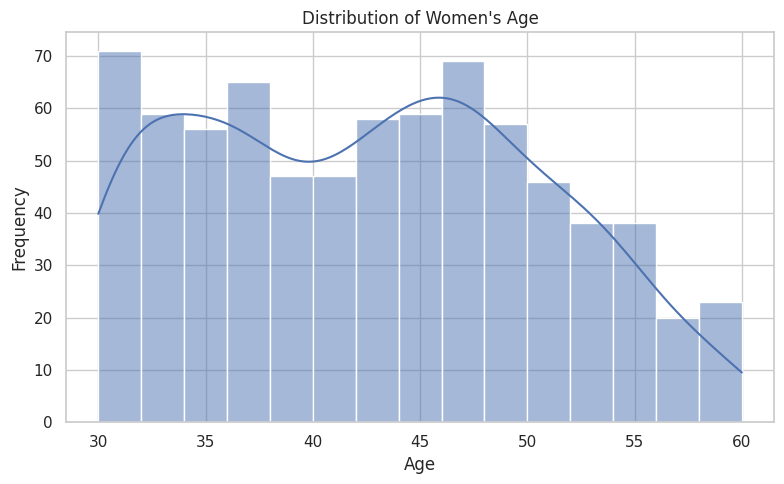

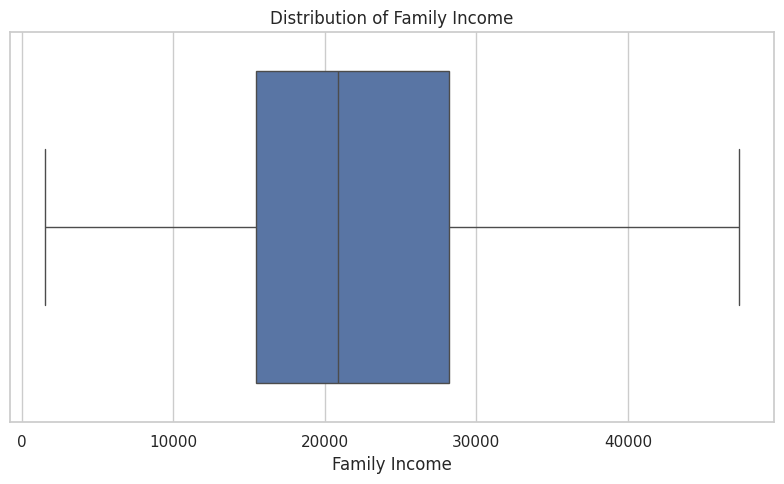

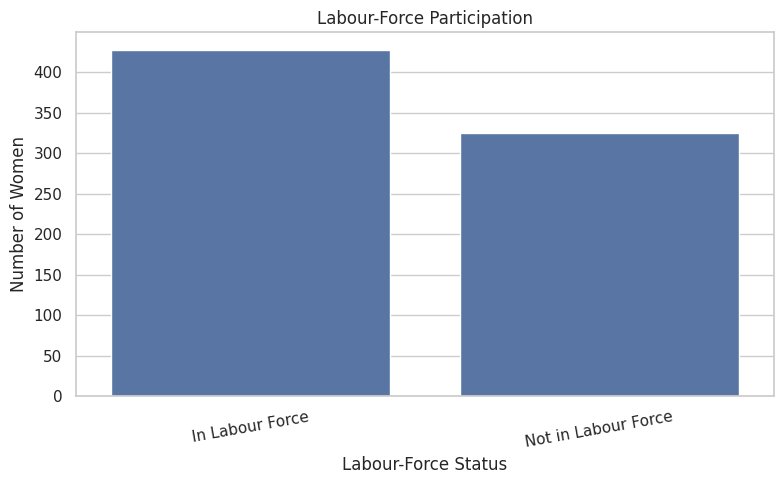

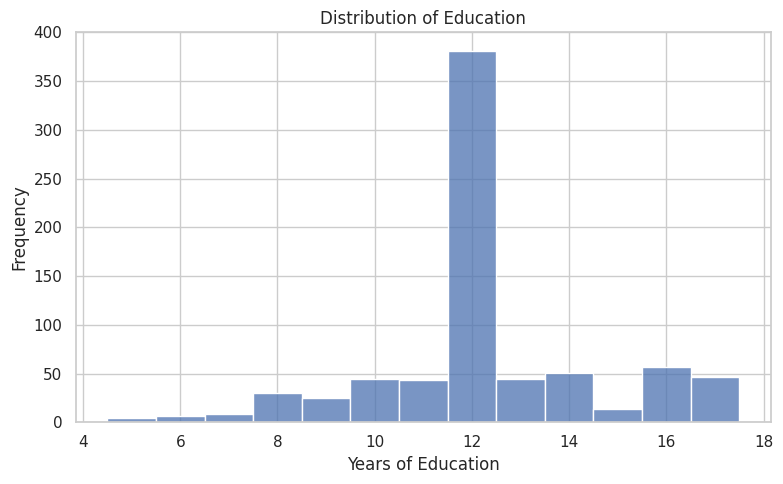

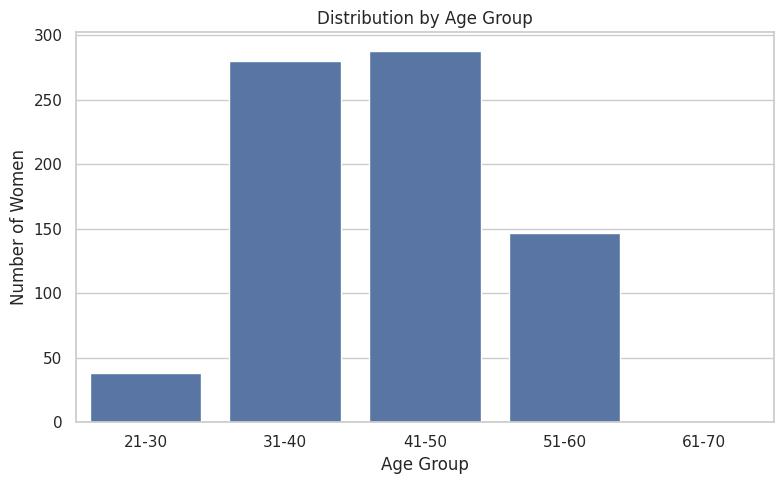

In [ ]:
# 6. UNIVARIATE ANALYSIS
# Minimum three visualizations



# Visualization 1: Histogram of age
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_transformed,
    x="age",
    bins=15,
    kde=True
)

plt.title("Distribution of Women's Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# Visualization 2: Box plot of family income
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_transformed,
    x="faminc"
)

plt.title("Distribution of Family Income")
plt.xlabel("Family Income")
plt.tight_layout()
plt.show()


# Visualization 3: Count plot of labour-force participation
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_transformed,
    x="labour_force_status"
)

plt.title("Labour-Force Participation")
plt.xlabel("Labour-Force Status")
plt.ylabel("Number of Women")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


# Visualization 4: Education distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_transformed,
    x="educ",
    bins=12,
    discrete=True
)

plt.title("Distribution of Education")
plt.xlabel("Years of Education")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# Visualization 5: Age-group count plot
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_transformed,
    x="age_group",
    order=["21-30", "31-40", "41-50", "51-60", "61-70"]
)

plt.title("Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Women")
plt.tight_layout()
plt.show()



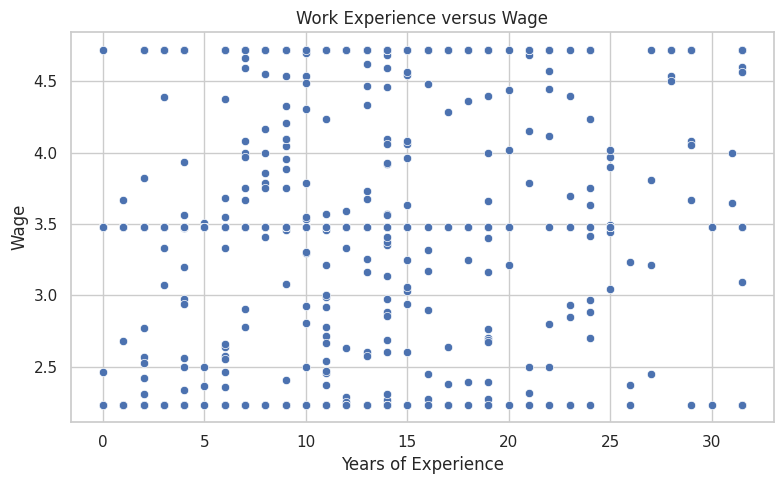

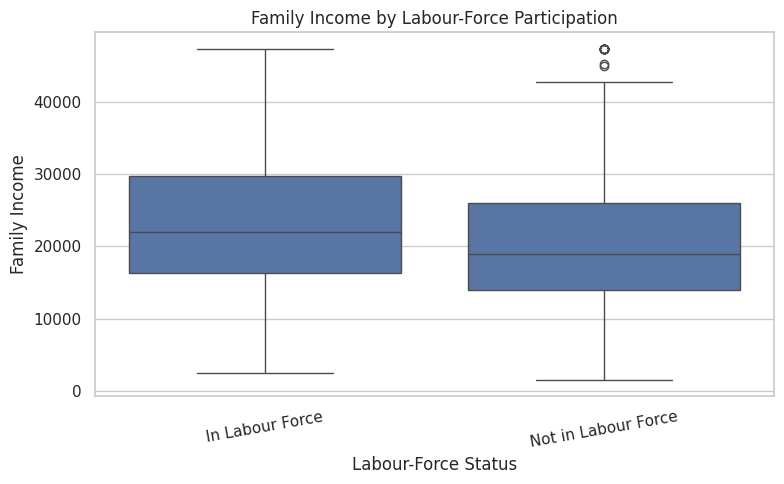

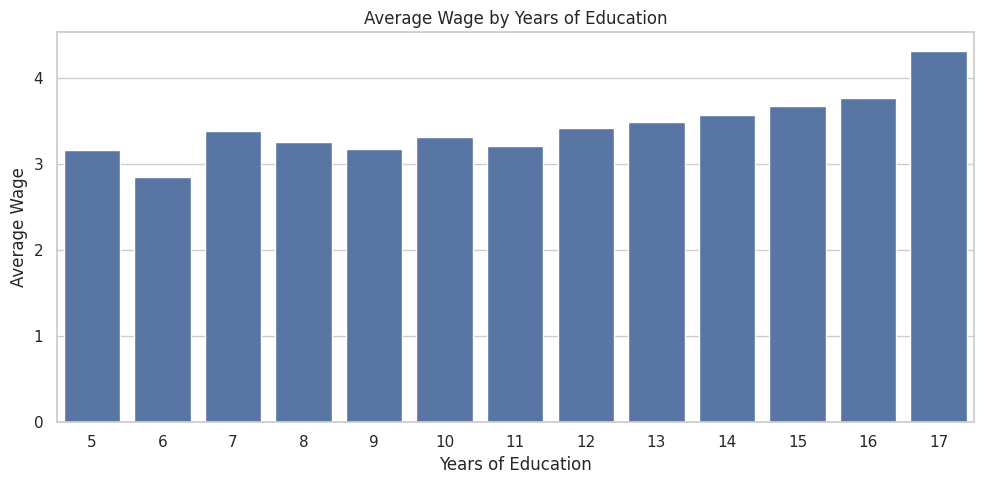

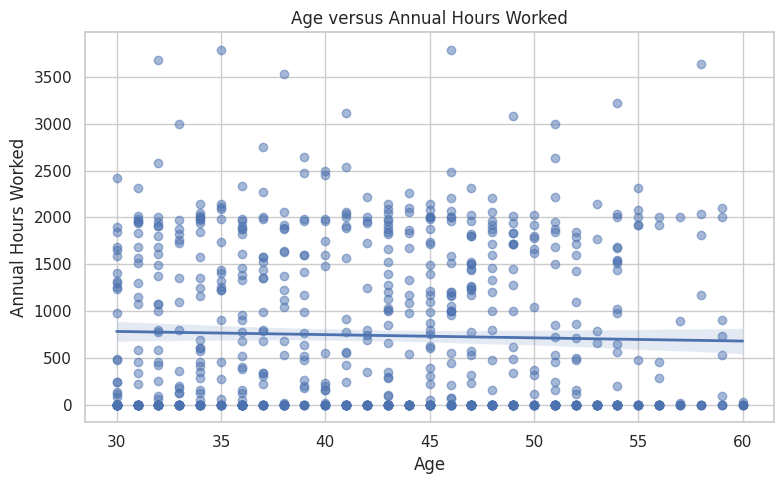

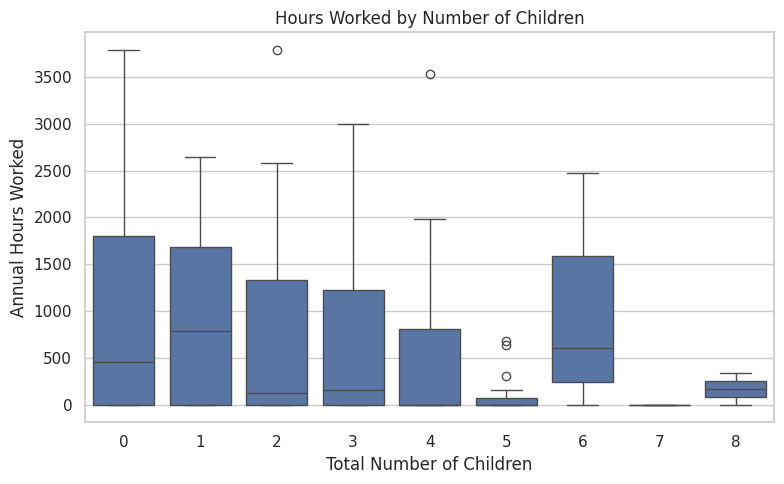

In [ ]:
# 7. BIVARIATE ANALYSIS
# Minimum three visualizations


# Visualization 1: Experience versus wage
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_transformed,
    x="exper",
    y="wage"
)

plt.title("Work Experience versus Wage")
plt.xlabel("Years of Experience")
plt.ylabel("Wage")
plt.tight_layout()
plt.show()


# Visualization 2: Labour-force participation versus family income
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_transformed,
    x="labour_force_status",
    y="faminc"
)

plt.title("Family Income by Labour-Force Participation")
plt.xlabel("Labour-Force Status")
plt.ylabel("Family Income")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


# Visualization 3: Education versus average wage
education_wage = (
    df_transformed
    .groupby("educ", as_index=False, observed=False)["wage"]
    .mean()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=education_wage,
    x="educ",
    y="wage"
)

plt.title("Average Wage by Years of Education")
plt.xlabel("Years of Education")
plt.ylabel("Average Wage")
plt.tight_layout()
plt.show()


# Visualization 4: Age versus hours worked
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df_transformed,
    x="age",
    y="hours",
    scatter_kws={"alpha": 0.5},
    line_kws={"linewidth": 2}
)

plt.title("Age versus Annual Hours Worked")
plt.xlabel("Age")
plt.ylabel("Annual Hours Worked")
plt.tight_layout()
plt.show()


# Visualization 5: Number of children versus hours worked
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_transformed,
    x="total_children",
    y="hours"
)

plt.title("Hours Worked by Number of Children")
plt.xlabel("Total Number of Children")
plt.ylabel("Annual Hours Worked")
plt.tight_layout()
plt.show()


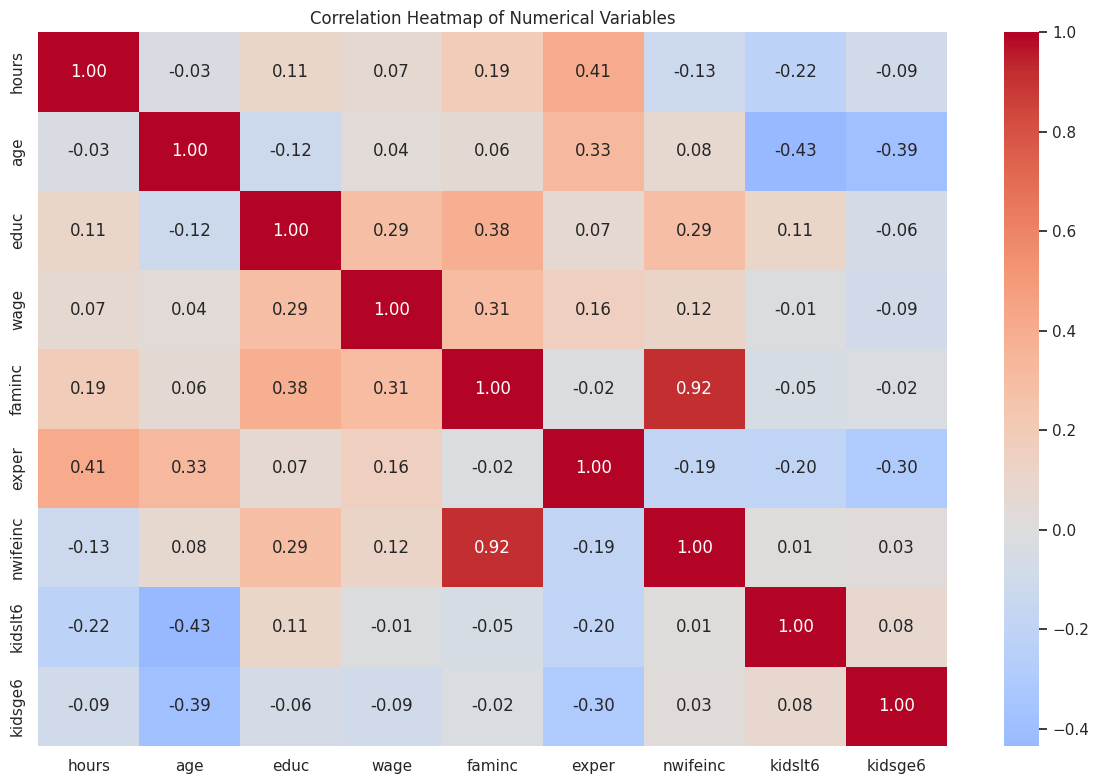

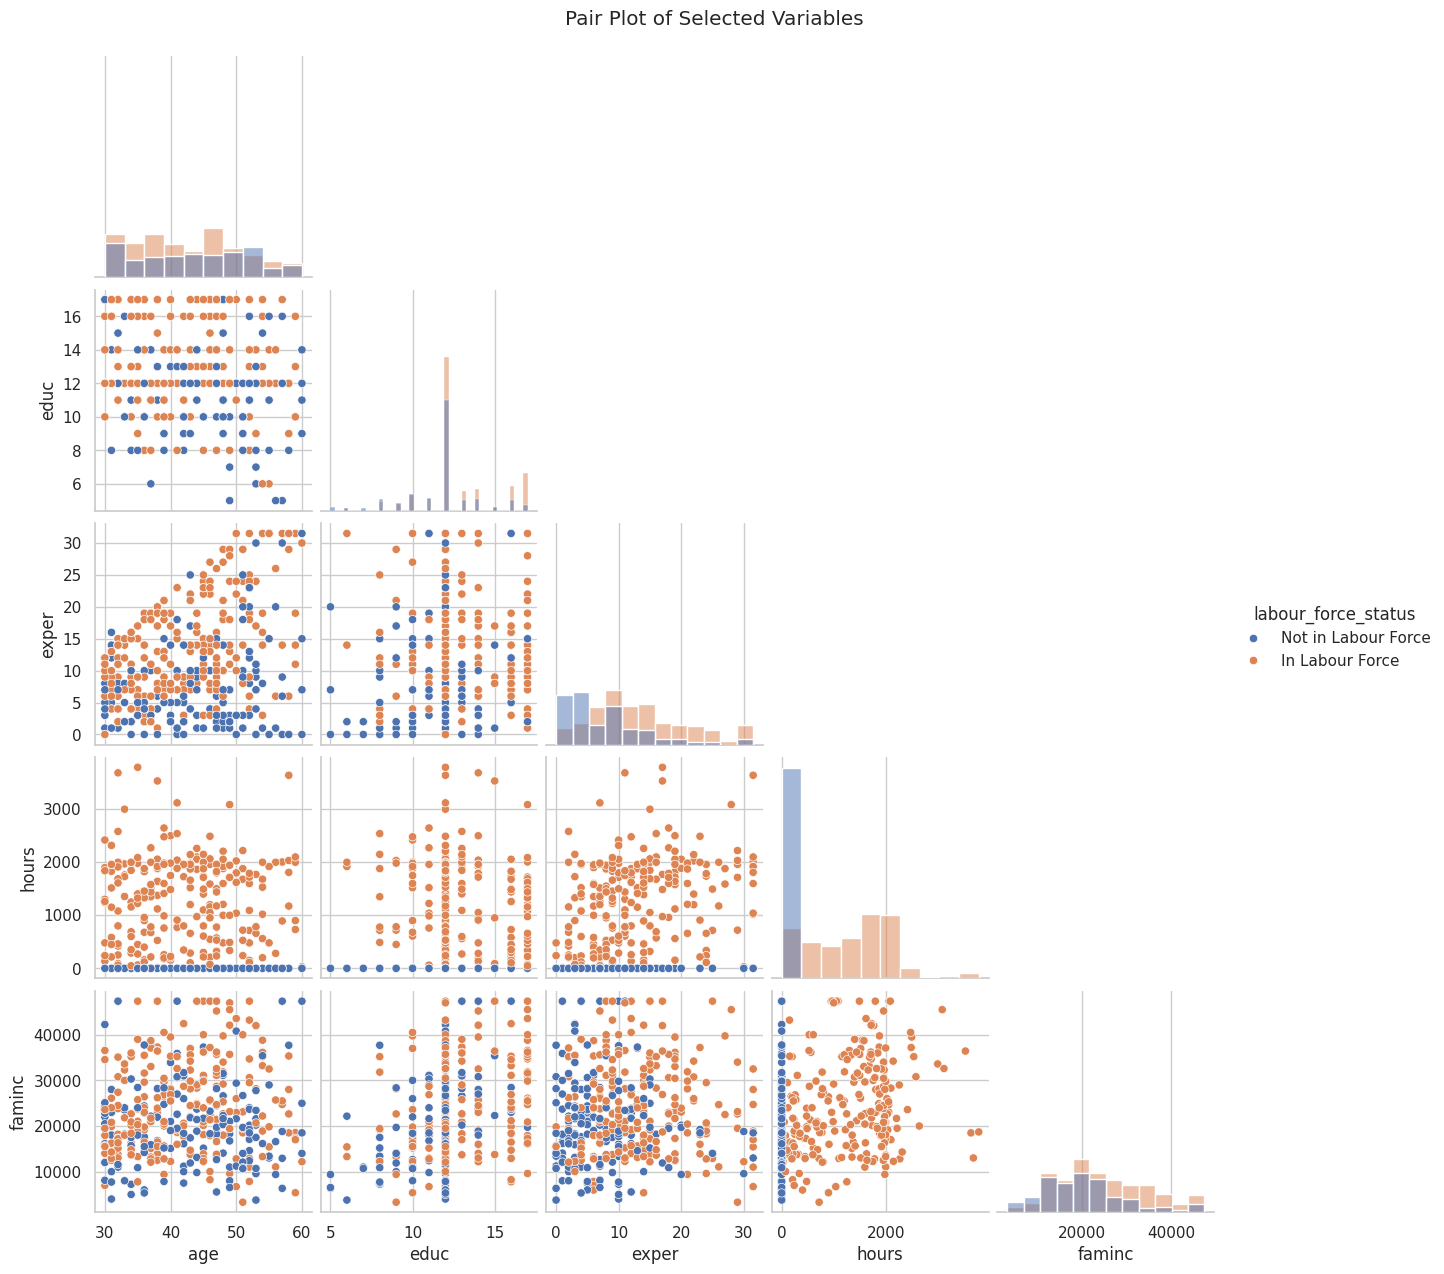

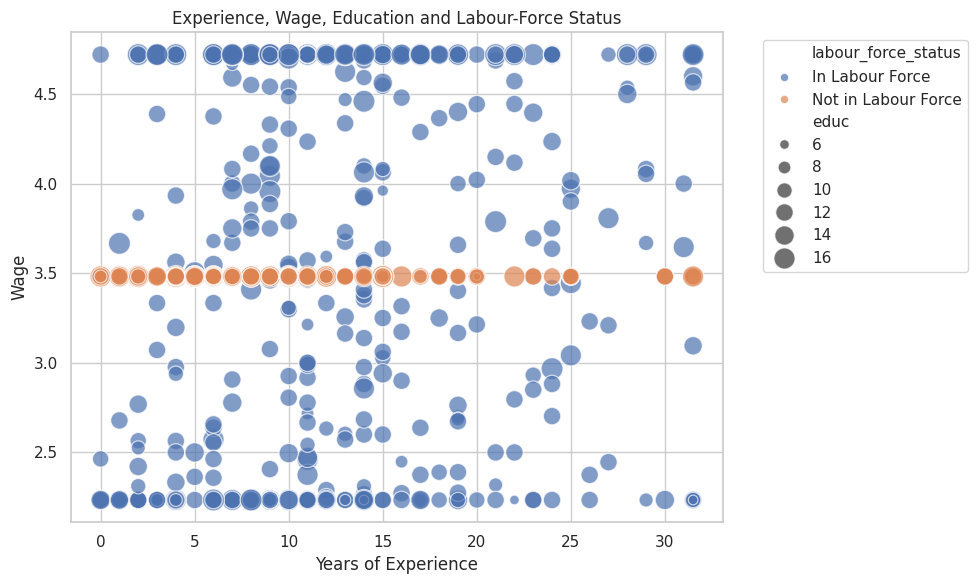

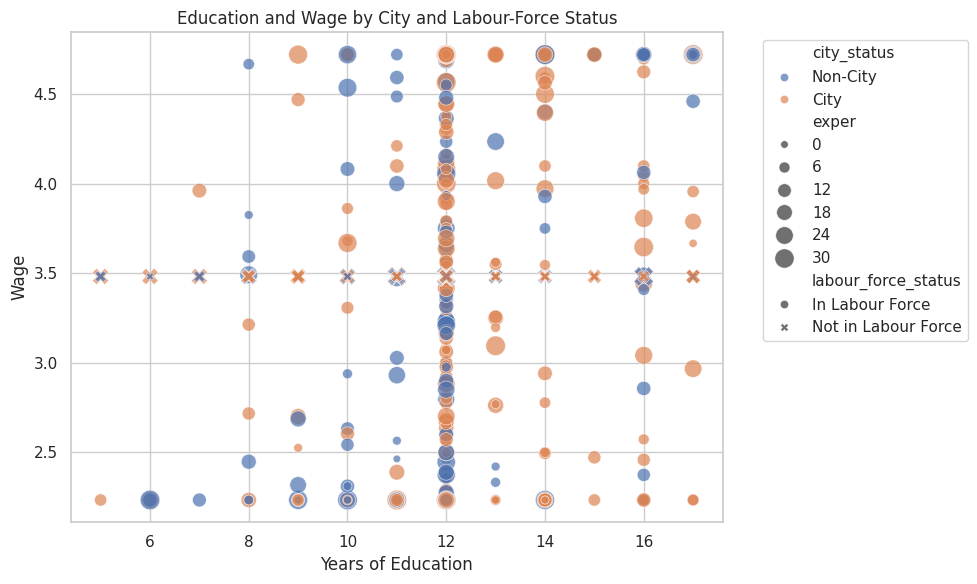

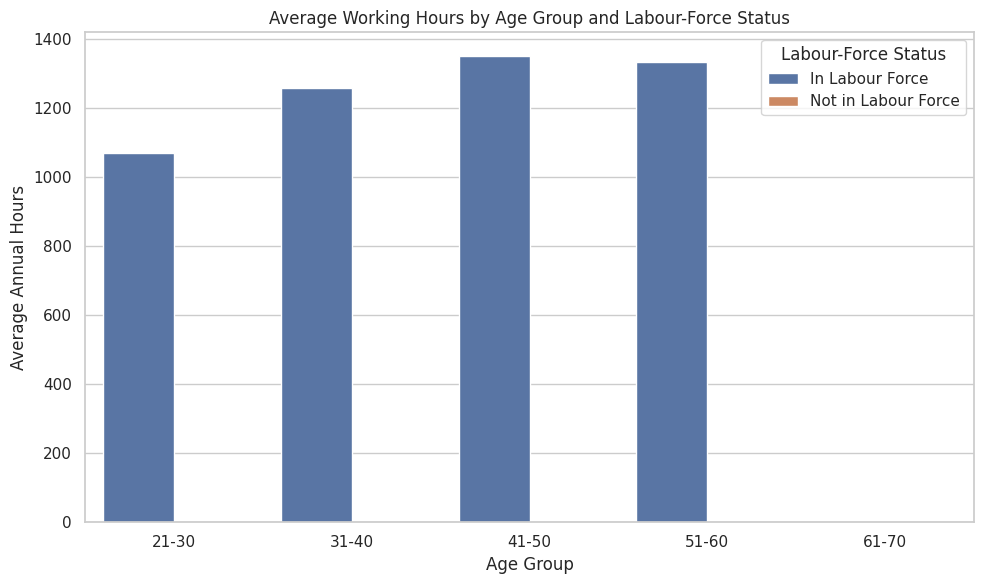

In [ ]:
# 8. MULTIVARIATE ANALYSIS
# Minimum three visualizations



# Visualization 1: Correlation heatmap
correlation_columns = [
    "hours",
    "age",
    "educ",
    "wage",
    "faminc",
    "exper",
    "nwifeinc",
    "kidslt6",
    "kidsge6"
]

available_correlation_columns = [
    column for column in correlation_columns
    if column in df_transformed.columns
]

correlation_matrix = df_transformed[
    available_correlation_columns
].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()


# Visualization 2: Pair plot
pairplot_columns = [
    "age",
    "educ",
    "exper",
    "hours",
    "faminc",
    "labour_force_status"
]

pairplot_data = df_transformed[
    pairplot_columns
].sample(
    n=min(400, len(df_transformed)),
    random_state=42
)

sns.pairplot(
    pairplot_data,
    hue="labour_force_status",
    diag_kind="hist",
    corner=True
)

plt.suptitle(
    "Pair Plot of Selected Variables",
    y=1.02
)

plt.show()


# Visualization 3: Multivariate scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_transformed,
    x="exper",
    y="wage",
    hue="labour_force_status",
    size="educ",
    sizes=(30, 250),
    alpha=0.7
)

plt.title(
    "Experience, Wage, Education and Labour-Force Status"
)

plt.xlabel("Years of Experience")
plt.ylabel("Wage")
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# Visualization 4: Education and wage by city status
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_transformed,
    x="educ",
    y="wage",
    hue="city_status",
    style="labour_force_status",
    size="exper",
    sizes=(30, 200),
    alpha=0.7
)

plt.title(
    "Education and Wage by City and Labour-Force Status"
)

plt.xlabel("Years of Education")
plt.ylabel("Wage")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# Visualization 5: Average hours by age group and labour status
age_hours = (
    df_transformed
    .groupby(
        ["age_group", "labour_force_status"],
        observed=False
    )["hours"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_hours,
    x="age_group",
    y="hours",
    hue="labour_force_status"
)

plt.title(
    "Average Working Hours by Age Group and Labour-Force Status"
)

plt.xlabel("Age Group")
plt.ylabel("Average Annual Hours")
plt.legend(title="Labour-Force Status")
plt.tight_layout()
plt.show()


In [1]:
#2 CAT 2 new 23BDS0018 PRATYAY MAJHI

## Google Colab is available in VS Code!
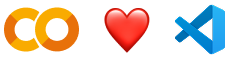

Try the new [Google Colab extension](https://marketplace.visualstudio.com/items?itemName=Google.colab) for Visual Studio Code. You can get up and running in just a few clicks:

*  In VS Code, open the ***Extensions*** view and search for 'Google Colab' to install.
*  Open the kernel selector by creating or opening any `.ipynb` notebook file in your local workspace and either running a cell or clicking the ***Select Kernel*** button in the top right.
*  Click ***Colab*** and then select your desired runtime, sign in with your Google account, and you're all set!

See more details in our [announcement blog here](https://developers.googleblog.com/google-colab-is-coming-to-vs-code).

## Access popular AI models via Google-Colab-AI Without an API Key
All users have access to most popular LLMs via the `google-colab-ai` Python library, and paid users have access to a wider selection of models. For more details, refer to the [getting started with google colab ai](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/Getting_started_with_google_colab_ai.ipynb).



In [ ]:
from google.colab import ai
response = ai.generate_text("What is the capital of France?")

## Explore the Gemini API
The Gemini API gives you access to Gemini models created by Google DeepMind. Gemini models are built from the ground up to be multimodal, so you can reason seamlessly across text, images, code, and audio.

**How to get started?**
*  Go to [Google AI Studio](https://aistudio.google.com/) and log in with your Google account.
*  [Create an API key](https://aistudio.google.com/app/apikey).
* Use a quickstart for [Python](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started.ipynb), or call the REST API using [curl](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/rest/Prompting_REST.ipynb).

**Discover Gemini's advanced capabilities**
*  Play with Gemini [multimodal outputs](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Image-out.ipynb), mixing text and images in an iterative way.
*  Discover the [multimodal Live API](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started_LiveAPI.ipynb ) (demo [here](https://aistudio.google.com/live)).
*  Learn how to [analyze images and detect items in your pictures](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Spatial_understanding.ipynb") using Gemini (bonus, there's a [3D version](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Spatial_understanding_3d.ipynb) as well!).
*  Unlock the power of [Gemini thinking model](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started_thinking.ipynb), capable of solving complex task with its inner thoughts.
      
**Explore complex use cases**
*  Use [Gemini grounding capabilities](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Search_grounding_for_research_report.ipynb) to create a report on a company based on what the model can find on internet.
*  Extract [invoices and form data from PDF](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Pdf_structured_outputs_on_invoices_and_forms.ipynb) in a structured way.
*  Create [illustrations based on a whole book](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Book_illustration.ipynb) using Gemini large context window and Imagen.

To learn more, check out the [Gemini cookbook](https://github.com/google-gemini/cookbook) or visit the [Gemini API documentation](https://ai.google.dev/docs/).


Colab now has AI features powered by [Gemini](https://gemini.google.com). The video below provides information on how to use these features, whether you're new to Python, or a seasoned veteran.

<center>
  <a href="https://www.youtube.com/watch?v=V7RXyqFUR98" target="_blank">
  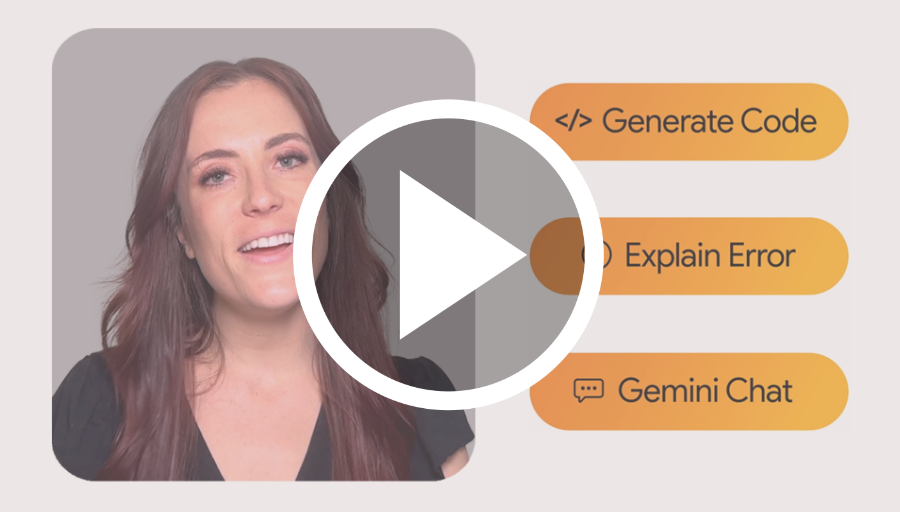
  </a>
</center>

<div class="markdown-google-sans">
  <h2>What is Colab?</h2>
</div>

Colab, or "Colaboratory", allows you to write and execute Python in your browser, with
- Zero configuration required
- Access to GPUs free of charge
- Easy sharing

Whether you're a **student**, a **data scientist** or an **AI researcher**, Colab can make your work easier. Watch [Introduction to Colab](https://www.youtube.com/watch?v=inN8seMm7UI) or [Colab Features You May Have Missed](https://www.youtube.com/watch?v=rNgswRZ2C1Y) to learn more, or just get started below!

<div class="markdown-google-sans">

## **Getting started**
</div>

The document you are reading is not a static web page, but an interactive environment called a **Colab notebook** that lets you write and execute code.

For example, here is a **code cell** with a short Python script that computes a value, stores it in a variable, and prints the result:

In [ ]:
seconds_in_a_day = 24 * 60 * 60
seconds_in_a_day

86400

To execute the code in the above cell, select it with a click and then either press the play button to the left of the code, or use the keyboard shortcut "Command/Ctrl+Enter". To edit the code, just click the cell and start editing.

Variables that you define in one cell can later be used in other cells:

In [ ]:
seconds_in_a_week = 7 * seconds_in_a_day
seconds_in_a_week

604800

Colab notebooks allow you to combine **executable code** and **rich text** in a single document, along with **images**, **HTML**, **LaTeX** and more. When you create your own Colab notebooks, they are stored in your Google Drive account. You can easily share your Colab notebooks with co-workers or friends, allowing them to comment on your notebooks or even edit them. To learn more, see [Overview of Colab](/notebooks/basic_features_overview.ipynb). To create a new Colab notebook you can use the File menu above, or use the following link: [create a new Colab notebook](http://colab.research.google.com#create=true).

Colab notebooks are Jupyter notebooks that are hosted by Colab. To learn more about the Jupyter project, see [jupyter.org](https://www.jupyter.org).

<div class="markdown-google-sans">

## Data science
</div>

With Colab you can harness the full power of popular Python libraries to analyze and visualize data. The code cell below uses **numpy** to generate some random data, and uses **matplotlib** to visualize it. To edit the code, just click the cell and start editing.

You can import your own data into Colab notebooks from your Google Drive account, including from spreadsheets, as well as from Github and many other sources. To learn more about importing data, and how Colab can be used for data science, see the links below under [Working with Data](#working-with-data).

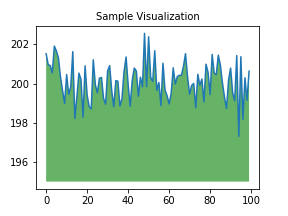

In [ ]:
import numpy as np
import IPython.display as display
from matplotlib import pyplot as plt
import io
import base64

ys = 200 + np.random.randn(100)
x = [x for x in range(len(ys))]

fig = plt.figure(figsize=(4, 3), facecolor='w')
plt.plot(x, ys, '-')
plt.fill_between(x, ys, 195, where=(ys > 195), facecolor='g', alpha=0.6)
plt.title("Sample Visualization", fontsize=10)

data = io.BytesIO()
plt.savefig(data)
image = F"data:image/png;base64,{base64.b64encode(data.getvalue()).decode()}"
alt = "Sample Visualization"
display.display(display.Markdown(F"""![{alt}]({image})"""))
plt.close(fig)

Colab notebooks execute code on Google's cloud servers, meaning you can leverage the power of Google hardware, including [GPUs and TPUs](#using-accelerated-hardware), regardless of the power of your machine. All you need is a browser.

For example, if you find yourself waiting for **pandas** code to finish running and want to go faster, you can switch to a GPU Runtime and use libraries like [RAPIDS cuDF](https://rapids.ai/cudf-pandas) that provide zero-code-change acceleration.

To learn more about accelerating pandas on Colab, see the [10 minute guide](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_colab_demo.ipynb) or
 [US stock market data analysis demo](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_stocks_demo.ipynb).

<div class="markdown-google-sans">

## Machine learning
</div>

With Colab you can import an image dataset, train an image classifier on it, and evaluate the model, all in just [a few lines of code](https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/quickstart/beginner.ipynb).

Colab is used extensively in the machine learning community with applications including:
- Getting started with TensorFlow
- Developing and training neural networks
- Experimenting with TPUs
- Disseminating AI research
- Creating tutorials

To see sample Colab notebooks that demonstrate machine learning applications, see the [machine learning examples](#machine-learning-examples) below.

<div class="markdown-google-sans">

## More Resources

### Working with Notebooks in Colab

</div>

- [Overview of Colab](/notebooks/basic_features_overview.ipynb)
- [Guide to Markdown](/notebooks/markdown_guide.ipynb)
- [Importing libraries and installing dependencies](/notebooks/snippets/importing_libraries.ipynb)
- [Saving and loading notebooks in GitHub](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/colab-github-demo.ipynb)
- [Interactive forms](/notebooks/forms.ipynb)
- [Interactive widgets](/notebooks/widgets.ipynb)

<div class="markdown-google-sans">

<a name="working-with-data"></a>
### Working with Data
</div>

- [Loading data: Drive, Sheets, and Google Cloud Storage](/notebooks/io.ipynb)
- [Charts: visualizing data](/notebooks/charts.ipynb)
- [Getting started with BigQuery](/notebooks/bigquery.ipynb)

<div class="markdown-google-sans">

### Machine Learning

<div>

These are a few of the notebooks related to Machine Learning, including Google's online Machine Learning course. See the [full course website](https://developers.google.com/machine-learning/crash-course/) for more.
- [Intro to Pandas DataFrame](https://colab.research.google.com/github/google/eng-edu/blob/main/ml/cc/exercises/pandas_dataframe_ultraquick_tutorial.ipynb)
- [Intro to RAPIDS cuDF to accelerate pandas](https://nvda.ws/rapids-cudf)
- [Getting Started with cuML's accelerator mode](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cuml_sklearn_colab_demo.ipynb)

<div class="markdown-google-sans">

<a name="using-accelerated-hardware"></a>
### Using Accelerated Hardware
</div>

- [Train a CNN to classify handwritten digits on the MNIST dataset using Flax NNX API](https://colab.research.google.com/github/google/flax/blob/main/docs_nnx/mnist_tutorial.ipynb)
- [Train a Vision Transformer (ViT) for image classification with JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_Vision_transformer.ipynb)
- [Text classification with a transformer language model using JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_transformer_text_classification.ipynb)

<div class="markdown-google-sans">

<a name="machine-learning-examples"></a>

### Featured examples

</div>

- [Train a miniGPT language model with JAX AI Stack](https://docs.jaxstack.ai/en/latest/JAX_for_LLM_pretraining.html)
- [LoRA/QLoRA finetuning for LLM using Tunix](https://github.com/google/tunix/blob/main/examples/qlora_gemma.ipynb)
- [Parameter-efficient fine-tuning of Gemma with LoRA and QLoRA](https://keras.io/examples/keras_recipes/parameter_efficient_finetuning_of_gemma_with_lora_and_qlora/)
- [Loading Hugging Face Transformers Checkpoints](https://keras.io/keras_hub/guides/hugging_face_keras_integration/)
- [8-bit Integer Quantization in Keras](https://keras.io/guides/int8_quantization_in_keras/)
- [Float8 training and inference with a simple Transformer model](https://keras.io/examples/keras_recipes/float8_training_and_inference_with_transformer/)
- [Pretraining a Transformer from scratch with KerasHub](https://keras.io/keras_hub/guides/transformer_pretraining/)
- [Simple MNIST convnet](https://keras.io/examples/vision/mnist_convnet/)
- [Image classification from scratch using Keras 3](https://keras.io/examples/vision/image_classification_from_scratch/)
- [Image Classification with KerasHub](https://keras.io/keras_hub/guides/classification_with_keras_hub/)
